# 02 — Analyse exploratoire hebdomadaire des consommations énergétiques

## Objectifs

Cette deuxième analyse exploratoire prolonge l'étude initiale réalisée
sur une période de 24 heures.

Elle s'appuie sur les mesures énergétiques fournies par l'API EnerVision
pour sept sites, sur une période de sept jours consécutifs.

Les objectifs sont les suivants :

- Vérifier la cohérence et la couverture temporelle des données.
- Étudier les variations de consommation d'un jour à l'autre.
- Comparer les comportements des sites entre jours ouvrés et week-ends.
- Identifier les cycles horaires récurrents.
- Évaluer la qualité des données sur une période plus longue.
- Identifier les variables pertinentes pour une prévision énergétique
  sur les prochaines 24 heures.

## Périmètre

- Source : API EnerVision (`/api/v1/readings`)
- Période : 7 jours
- Sites : SITE001 à SITE007
- Volume attendu : 1 000 observations par site
- Stockage : `data/raw/7d/`

Les données utilisées sont synthétiques. Les conclusions devront donc
être interprétées en tenant compte du fonctionnement du générateur.

## Prérequis

La collecte doit avoir été réalisée avant l'exécution du notebook :

`python scripts/collect_readings.py --days 7`

Le notebook exploite exclusivement les fichiers JSON déjà enregistrés.
Il ne déclenche aucun appel à l'API.

A - Import et chargement fichiers hebdos

In [29]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

# Notebook exécuté depuis ml/notebooks/
data_dir = Path("../data/raw/7d")

files = sorted(data_dir.glob("SITE*.json"))

if not files:
    raise FileNotFoundError(
        f"Aucun fichier trouvé dans {data_dir}. "
        "Exécuter d'abord : python scripts/collect_readings.py --days 7"
    )

records = []

for file in files:
    with file.open("r", encoding="utf-8") as f:
        payload = json.load(f)

    for reading in payload["readings"]:
        records.append(
            {
                **reading,
                "collected_at": payload["collected_at"],
                "source_file": file.name,
            }
        )

df = pd.DataFrame(records)

df["timestamp"] = pd.to_datetime(df["timestamp"], utc=True)
df["collected_at"] = pd.to_datetime(df["collected_at"], utc=True)

print(f"Nombre de fichiers : {len(files)}")
print(f"Nombre d'observations : {len(df)}")
print(f"Nombre de sites : {df['site_id'].nunique()}")

display(df.head())

Nombre de fichiers : 7
Nombre d'observations : 7000
Nombre de sites : 7


,timestamp,site_id,site_type,consumption_kw,consumption_kwh,voltage_v,current_a,power_factor,temperature_celsius,humidity_percent,null_reasons,data_quality,collected_at,source_file
0,2026-10-15 12:25:00.035397+00:00,SITE001,office,166.06,166.06,401.7,251.22,0.881,7.5,50.2,[],good,2026-10-22 12:30:00.035397+00:00,SITE001_20261022_123000.json
1,2026-10-15 12:35:04.835397+00:00,SITE001,office,174.21,174.21,398.9,265.43,0.980,13.2,44.9,[],good,2026-10-22 12:30:00.035397+00:00,SITE001_20261022_123000.json
2,2026-10-15 12:45:09.635397+00:00,SITE001,office,NaN,NaN,390.3,262.51,0.933,10.5,50.5,[consumption_sensor_failure],partial,2026-10-22 12:30:00.035397+00:00,SITE001_20261022_123000.json
3,2026-10-15 12:55:14.435397+00:00,SITE001,office,176.02,176.02,402.9,265.50,0.913,10.5,43.8,[],good,2026-10-22 12:30:00.035397+00:00,SITE001_20261022_123000.json
4,2026-10-15 13:05:19.235397+00:00,SITE001,office,NaN,NaN,397.8,250.51,0.939,7.6,45.9,[consumption_sensor_failure],partial,2026-10-22 12:30:00.035397+00:00,SITE001_20261022_123000.json


B - Vérification initiale

In [30]:
summary = (
    df.groupby("site_id")
    .agg(
        observations=("timestamp", "size"),
        first_timestamp=("timestamp", "min"),
        last_timestamp=("timestamp", "max"),
        missing_consumption=("consumption_kw", lambda x: x.isna().sum()),
    )
    .reset_index()
)

summary["duration_days"] = (
    summary["last_timestamp"] - summary["first_timestamp"]
).dt.total_seconds() / 86400

display(summary)

,site_id,observations,first_timestamp,last_timestamp,missing_consumption,duration_days
0,SITE001,1000,2026-10-15 12:25:00.035397+00:00,2026-10-22 12:14:55.235397+00:00,73,6.993
1,SITE002,1000,2026-10-15 12:25:00.035397+00:00,2026-10-22 12:14:55.235397+00:00,69,6.993
2,SITE003,1000,2026-10-15 12:25:00.035397+00:00,2026-10-22 12:14:55.235397+00:00,73,6.993
3,SITE004,1000,2026-10-15 12:25:00.035397+00:00,2026-10-22 12:14:55.235397+00:00,61,6.993
4,SITE005,1000,2026-10-15 12:25:00.035397+00:00,2026-10-22 12:14:55.235397+00:00,57,6.993
5,SITE006,1000,2026-10-15 12:25:00.035397+00:00,2026-10-22 12:14:55.235397+00:00,55,6.993
6,SITE007,1000,2026-10-15 12:25:00.035397+00:00,2026-10-22 12:14:55.235397+00:00,62,6.993


### Conclusion — Validation du jeu de données

La collecte hebdomadaire a permis de constituer un jeu de données
de 7 000 observations, réparties équitablement entre sept sites.

Les observations couvrent une période d'environ sept jours,
du 15 au 22 octobre 2026, avec des bornes temporelles identiques
pour l'ensemble des sites.

Au total, 450 observations (6,43 %) présentent une valeur manquante
pour la consommation électrique.

La structure du jeu de données est conforme aux attentes et permet
de poursuivre l'analyse des comportements énergétiques hebdomadaires.

## 2 — Couverture temporelle et répartition des observations

Cette section vise à vérifier la régularité des mesures et leur
répartition entre les différents jours de la semaine.

L'objectif est notamment de s'assurer que les données permettent
une comparaison pertinente entre jours ouvrés et week-ends.

A - Analyse de couverture des sites pour l'ensemble de la semaine

In [31]:
# Extraction des caractéristiques temporelles
df["date"] = df["timestamp"].dt.date
df["day_of_week"] = df["timestamp"].dt.dayofweek
df["hour"] = df["timestamp"].dt.hour
df["is_weekend"] = df["day_of_week"] >= 5

# Nombre d'observations par jour et par site
daily_counts = df.groupby(["date", "site_id"]).size().unstack("site_id", fill_value=0)

display(daily_counts)

# Vérification de la régularité des intervalles
intervals = (
    df.sort_values(["site_id", "timestamp"])
    .groupby("site_id")["timestamp"]
    .diff()
    .dt.total_seconds()
)

print("Intervalle minimum :", intervals.min(), "secondes")
print("Intervalle moyen :", intervals.mean(), "secondes")
print("Intervalle maximum :", intervals.max(), "secondes")

site_id,SITE001,SITE002,SITE003,SITE004,SITE005,SITE006,SITE007
date,,,,,,,
2026-10-15,69,69,69,69,69,69,69
2026-10-16,143,143,143,143,143,143,143
2026-10-17,143,143,143,143,143,143,143
2026-10-18,143,143,143,143,143,143,143
2026-10-19,143,143,143,143,143,143,143
2026-10-20,143,143,143,143,143,143,143
2026-10-21,143,143,143,143,143,143,143
2026-10-22,73,73,73,73,73,73,73


Intervalle minimum : 604.8 secondes
Intervalle moyen : 604.8000000000001 secondes
Intervalle maximum : 604.8 secondes


### Conclusion — Couverture temporelle

L'analyse confirme que les 7 000 observations sont réparties sur
une grille temporelle régulière et commune aux sept sites.

Chaque site dispose de 1 000 observations espacées exactement
de 604,8 secondes, soit environ 10 minutes.

La période étudiée comprend six journées calendaires complètes
et deux journées partielles, avec un samedi et un dimanche complets.

Cette couverture permet d'engager une première comparaison entre
jours ouvrés et week-end.

La régularité parfaite des timestamps suggère également que l'API
génère une grille temporelle en fonction de la période demandée
et du nombre maximal de mesures.

Enfin, les valeurs manquantes ne provoquent pas de rupture dans
la séquence temporelle : elles correspondent à des observations
présentes dont certaines mesures sont absentes.

Ces caractéristiques devront être prises en compte lors de la
préparation des séries temporelles destinées au Machine Learning.

## 3 — Analyse des profils de consommation hebdomadaires

L'objectif de cette section est d'observer l'évolution de la consommation
électrique de chaque site sur l'ensemble de la semaine.

Nous chercherons notamment à identifier :

- La répétition éventuelle des cycles journaliers.
- Les différences de comportement entre jours ouvrés et week-end.
- Les périodes de faible activité ou d'arrêt apparent.
- Les particularités propres aux différentes catégories de bâtiments.

Cette analyse prolonge les observations du notebook 01 sans reprendre
l'étude générale des distributions et des corrélations.

A - Visualisation de la consommation des sept sites pour une semaine

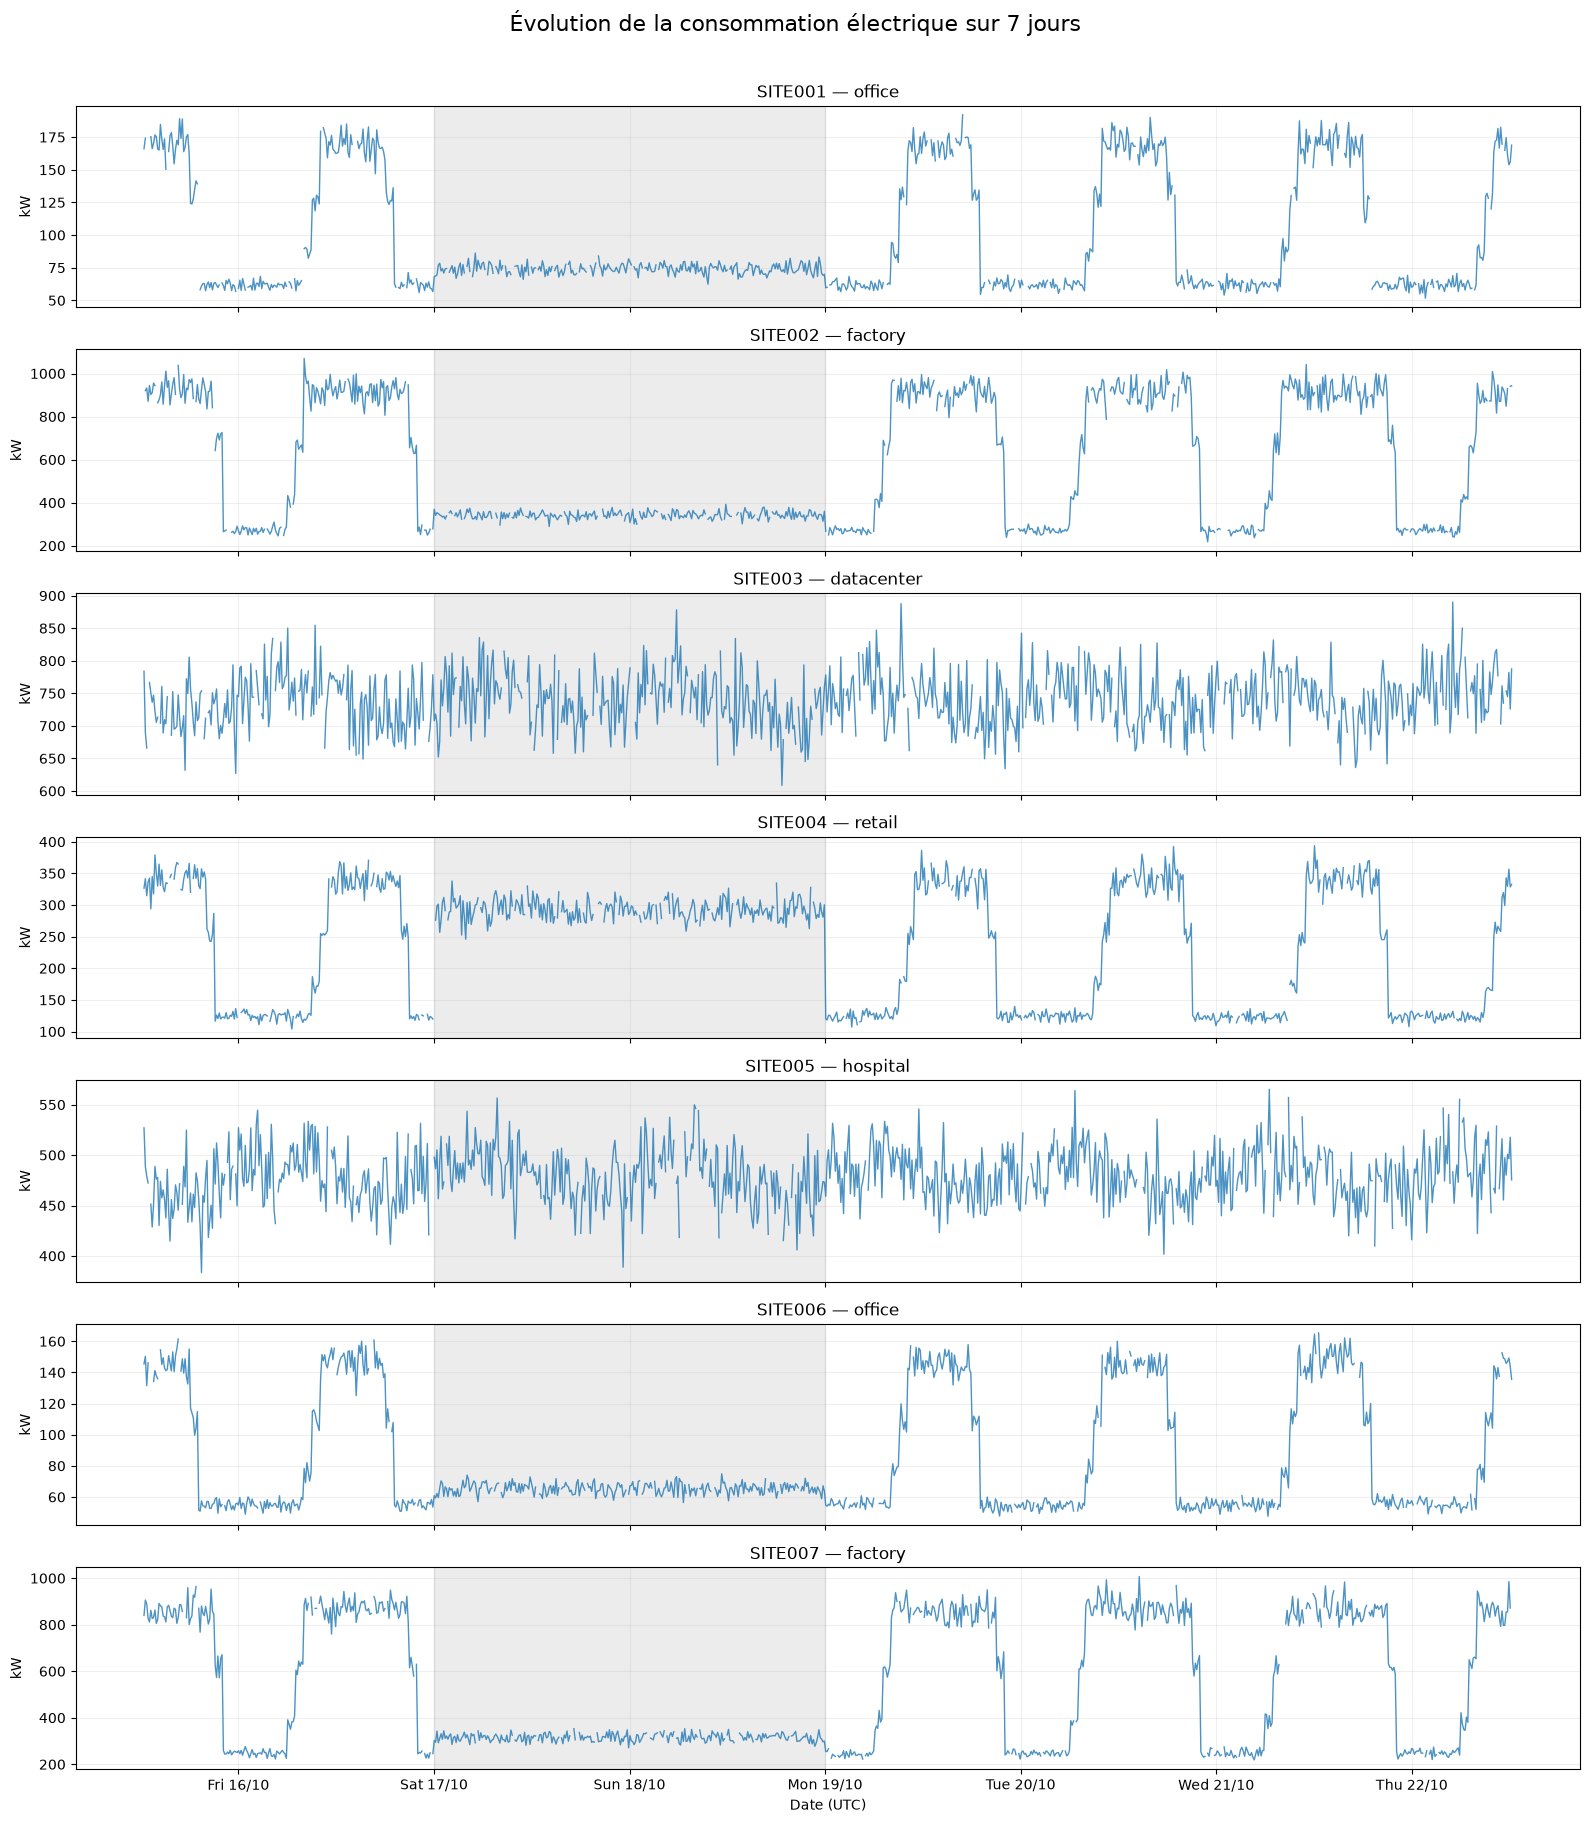

In [32]:
import matplotlib.dates as mdates

sites = sorted(df["site_id"].unique())

fig, axes = plt.subplots(
    nrows=len(sites),
    ncols=1,
    figsize=(16, 18),
    sharex=True,
)

for ax, site_id in zip(axes, sites):
    site_data = df[df["site_id"] == site_id].sort_values("timestamp")

    site_type = site_data["site_type"].iloc[0]

    ax.plot(
        site_data["timestamp"],
        site_data["consumption_kw"],
        linewidth=1,
        alpha=0.8,
    )

    # Mise en évidence du week-end
    weekend_start = pd.Timestamp("2026-10-17", tz="UTC")
    weekend_end = pd.Timestamp("2026-10-19", tz="UTC")

    ax.axvspan(
        weekend_start,
        weekend_end,
        color="gray",
        alpha=0.15,
    )

    ax.set_title(f"{site_id} — {site_type}")
    ax.set_ylabel("kW")
    ax.grid(alpha=0.2)

axes[-1].xaxis.set_major_locator(mdates.DayLocator())
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%a %d/%m", tz=mdates.UTC))

plt.suptitle(
    "Évolution de la consommation électrique sur 7 jours",
    fontsize=16,
    y=1.01,
)

plt.xlabel("Date (UTC)")
plt.tight_layout()
plt.show()

### Conclusion — Profils de consommation hebdomadaires

L'observation des courbes de consommation sur sept jours met en évidence
des comportements hebdomadaires distincts selon les catégories de bâtiments.

Les bureaux (SITE001 et SITE006) et les usines (SITE002 et SITE007)
présentent des cycles journaliers marqués pendant les jours ouvrés.
Ces cycles disparaissent durant le week-end, au profit d'une consommation
résiduelle relativement stable.

Le commerce (SITE004) présente un comportement différent, avec une
consommation soutenue pendant le week-end, sans les variations horaires
observées en semaine.

À l'inverse, le datacenter (SITE003) et l'hôpital (SITE005) maintiennent
une consommation relativement constante sur l'ensemble de la période,
sans interruption hebdomadaire identifiable.

Ces observations suggèrent que le jour de la semaine et le statut
week-end peuvent constituer des variables explicatives pertinentes,
mais que leur influence dépend fortement de la catégorie du site.

Elles renforcent ainsi l'intérêt d'intégrer conjointement les
caractéristiques temporelles et le type de bâtiment dans les futurs
modèles de prévision énergétique.

Ces conclusions restent exploratoires, puisqu'elles reposent sur
un unique week-end et sur des données synthétiques.

## 4 — Comparaison des consommations entre jours ouvrés et week-end

L'analyse des courbes hebdomadaires a mis en évidence des comportements distincts selon les catégories de bâtiments. Les bureaux et les usines semblent notamment présenter une réduction importante de leur activité pendant le week-end, contrairement aux commerces, aux hôpitaux et aux datacenters.

Afin de compléter ces observations visuelles, nous allons comparer les consommations moyennes de chaque site entre les jours ouvrés et le week-end.

Cette analyse vise à :

- Quantifier les écarts de consommation entre les deux périodes.
- Identifier les catégories de bâtiments les plus sensibles au cycle hebdomadaire.
- Évaluer la pertinence des variables temporelles `day_of_week` et `is_weekend` pour nos futurs modèles de prévision.

Les résultats devront être interprétés avec prudence, puisqu'ils reposent sur une seule semaine de données synthétiques. Les moyennes des jours ouvrés intègrent également deux journées calendaires partielles.

In [33]:
# Comparaison des consommations moyennes
# entre jours ouvrés et week-end

weekly_comparison = (
    df.groupby(["site_id", "site_type", "is_weekend"])["consumption_kw"]
    .mean()
    .unstack("is_weekend")
    .rename(
        columns={
            False: "weekday_mean_kw",
            True: "weekend_mean_kw",
        }
    )
)

weekly_comparison["difference_pct"] = (
    (weekly_comparison["weekend_mean_kw"] - weekly_comparison["weekday_mean_kw"])
    / weekly_comparison["weekday_mean_kw"]
    * 100
)

display(weekly_comparison.round(2))

,is_weekend,weekday_mean_kw,weekend_mean_kw,difference_pct
site_id,site_type,,,
SITE001,office,104.95,74.16,-29.34
SITE002,factory,663.63,342.43,-48.40
SITE003,datacenter,739.87,739.45,-0.06
SITE004,retail,217.28,292.75,34.73
SITE005,hospital,479.03,478.74,-0.06
SITE006,office,90.60,65.41,-27.80
SITE007,factory,620.46,315.49,-49.15


### Conclusion — Comparaison jours ouvrés / week-end

La comparaison des consommations moyennes confirme les différences de comportement identifiées lors de l'analyse graphique.

Les usines présentent les réductions les plus importantes pendant le week-end, avec une baisse d'environ 49 % pour les deux sites étudiés. Les bureaux affichent également une diminution significative, comprise entre 28 et 29 %.

À l'inverse, le commerce présente une augmentation de 34,73 % de sa consommation moyenne pendant le week-end, tandis que le datacenter et l'hôpital conservent des niveaux pratiquement identiques entre les deux périodes.

Ces résultats mettent en évidence **l'existence de profils hebdomadaires fortement dépendants de la catégorie de bâtiment**. Ils suggèrent que les variables `day_of_week`, `is_weekend` et `site_type` pourraient jouer un rôle important dans les futurs modèles de prévision.

Toutefois, cette analyse repose sur un unique week-end et ne permet pas de déterminer directement les périodes d'ouverture ou de fermeture des établissements. Les différences observées devront être confrontées aux métadonnées disponibles et, si possible, à des périodes d'observation supplémentaires.

### Conclusion — Comparaison jours ouvrés / week-end

La comparaison des consommations moyennes confirme les différences de comportement identifiées lors de l'analyse graphique.

Les usines présentent les réductions les plus importantes pendant le week-end, avec une baisse d'environ 49 % pour les deux sites étudiés. Les bureaux affichent également une diminution significative, comprise entre 28 et 29 %.

À l'inverse, le commerce présente une augmentation de 34,73 % de sa consommation moyenne pendant le week-end, tandis que le datacenter et l'hôpital conservent des niveaux pratiquement identiques entre les deux périodes.

Ces résultats mettent en évidence **l'existence de profils hebdomadaires fortement dépendants de la catégorie de bâtiment**. Ils suggèrent que les variables `day_of_week`, `is_weekend` et `site_type` pourraient jouer un rôle important dans les futurs modèles de prévision.

Toutefois, cette analyse repose sur un unique week-end et ne permet pas de déterminer directement les périodes d'ouverture ou de fermeture des établissements. Les différences observées devront être confrontées aux métadonnées disponibles et, si possible, à des périodes d'observation supplémentaires.

## 5 — Analyse des profils horaires : jours ouvrés et week-end

Les analyses précédentes ont mis en évidence des variations significatives de consommation entre les jours ouvrés et le week-end, particulièrement pour les bureaux, les usines et le commerce.

Cette section vise à approfondir ces observations en comparant les profils horaires moyens de chaque site selon le type de journée.

L'objectif est de déterminer si les variations hebdomadaires correspondent à une simple modification du niveau de consommation ou à un changement plus important du cycle d'activité.

Cette analyse permettra également d'évaluer l'intérêt de combiner les variables `hour`, `is_weekend` et `site_type` dans les futurs modèles de prévision énergétique à 24 heures.

A - Calcul des profils horaires
- Regroupement des consommations par site, par heure et par type de journée

In [34]:
hourly_profiles = (
    df.groupby(["site_id", "site_type", "is_weekend", "hour"])["consumption_kw"]
    .mean()
    .reset_index()
)

display(hourly_profiles.head(10))

,site_id,site_type,is_weekend,hour,consumption_kw
0,SITE001,office,False,0,61.477200
1,SITE001,office,False,1,61.593571
2,SITE001,office,False,2,61.961071
3,SITE001,office,False,3,61.955357
4,SITE001,office,False,4,61.190000
5,SITE001,office,False,5,61.721724
6,SITE001,office,False,6,62.334074
7,SITE001,office,False,7,61.659200
8,SITE001,office,False,8,87.015333
9,SITE001,office,False,9,128.778889


B - Visualisation comparative

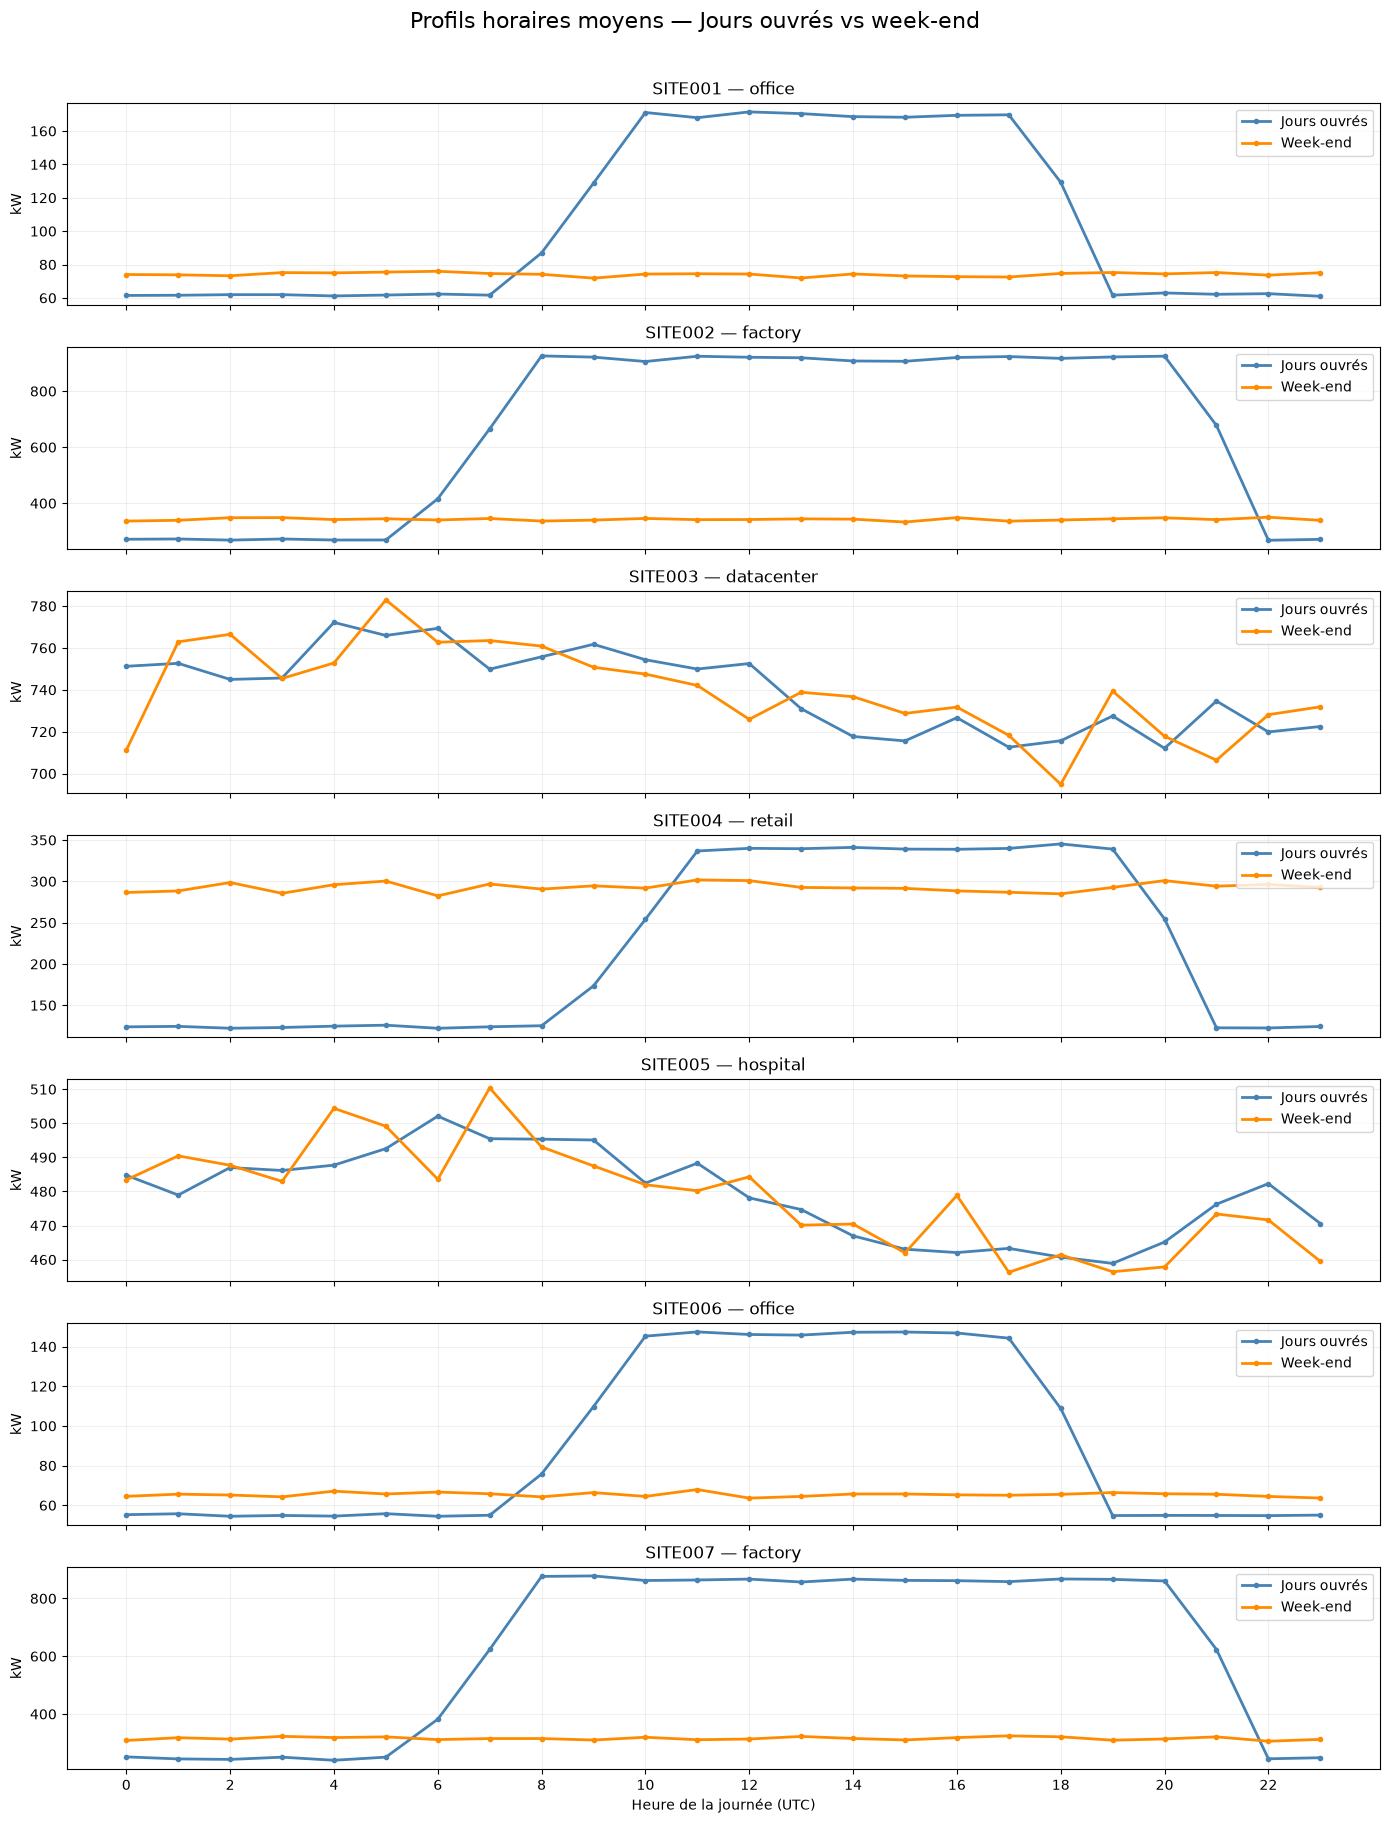

In [35]:
sites = sorted(df["site_id"].unique())

fig, axes = plt.subplots(
    nrows=len(sites),
    ncols=1,
    figsize=(14, 18),
    sharex=True,
)

for ax, site_id in zip(axes, sites):
    site_data = hourly_profiles[hourly_profiles["site_id"] == site_id]

    site_type = site_data["site_type"].iloc[0]

    for is_weekend, label, color in [
        (False, "Jours ouvrés", "steelblue"),
        (True, "Week-end", "darkorange"),
    ]:
        profile = site_data[site_data["is_weekend"] == is_weekend]

        ax.plot(
            profile["hour"],
            profile["consumption_kw"],
            label=label,
            color=color,
            linewidth=2,
            marker="o",
            markersize=3,
        )

    ax.set_title(f"{site_id} — {site_type}")
    ax.set_ylabel("kW")
    ax.set_xticks(range(0, 24, 2))
    ax.grid(alpha=0.2)
    ax.legend(loc="upper right")

axes[-1].set_xlabel("Heure de la journée (UTC)")

plt.suptitle(
    "Profils horaires moyens — Jours ouvrés vs week-end",
    fontsize=16,
    y=1.01,
)

plt.tight_layout()
plt.show()

### Conclusion — Comparaison des profils horaires

L'analyse des profils horaires moyens confirme que les comportements énergétiques diffèrent sensiblement selon les catégories de bâtiments et le type de journée.

Les bureaux et les usines présentent des cycles d'activité très marqués pendant les jours ouvrés, caractérisés par une forte augmentation de la consommation en journée. Ces cycles disparaissent pendant le week-end, au profit d'une consommation résiduelle relativement stable.

Le commerce présente un comportement particulier : alors que sa consommation suit un cycle journalier marqué en semaine, elle reste élevée et quasiment constante pendant le week-end.

À l'inverse, les profils horaires du datacenter et de l'hôpital restent relativement similaires entre jours ouvrés et week-end, sans rupture d'activité identifiable.

Ces observations montrent que **l'effet du week-end ne se limite pas à une variation du niveau moyen de consommation : il peut également modifier la forme du cycle journalier**.

Elles renforcent l'intérêt d'utiliser conjointement les variables `hour`, `day_of_week` et `site_type` dans les futurs modèles de prévision énergétique.

Toutefois, ces résultats reposent sur une seule semaine de données synthétiques. Ils devront être confirmés sur une période plus longue avant de pouvoir être considérés comme représentatifs d'un comportement énergétique réel.

## 6 — Conclusion générale et perspectives

Cette deuxième analyse exploratoire, réalisée sur 7 000 observations réparties entre sept sites et couvrant une semaine, a permis de compléter les enseignements de la première étude en mettant en évidence l'influence des cycles hebdomadaires sur la consommation énergétique.

Les résultats montrent que les comportements diffèrent fortement selon les catégories de bâtiments. Les bureaux et les usines présentent une réduction importante de leur consommation pendant le week-end, tandis que le commerce conserve une consommation élevée et que les infrastructures fonctionnant en continu, comme l'hôpital et le datacenter, présentent des profils relativement stables.

Au-delà des variations de consommation moyenne, l'analyse révèle que **les cycles horaires eux-mêmes peuvent être modifiés selon le jour de la semaine**. Cette observation constitue un enseignement important pour la conception du futur modèle prédictif.

### Implications pour le Machine Learning

Cette exploration permet d'identifier plusieurs variables candidates pour la construction du dataset analytique :

- `hour` : identifier les cycles journaliers.
- `day_of_week` : distinguer les comportements selon le jour.
- `is_weekend` : caractériser explicitement les périodes de week-end.
- `site_type` et `site_id` : prendre en compte les spécificités des bâtiments.
- `is_scheduled_active` : représenter une période d'activité théorique, sous réserve de disposer de règles métier fiables.

Ces variables seront construites ou préparées lors de la phase de feature engineering. Leur pertinence devra ensuite être évaluée expérimentalement pendant l'entraînement.

L'étude confirme également l'intérêt d'envisager des modèles capables de prendre en compte les interactions entre caractéristiques temporelles et catégories de bâtiments.

### Limites et perspectives

Les observations reposent sur une unique semaine de données synthétiques. Elles permettent d'identifier des tendances, mais ne suffisent pas à démontrer leur stabilité dans le temps.

Par ailleurs, les données disponibles ne permettent pas de déterminer directement l'état historique d'ouverture ou de fermeture des sites. Une éventuelle variable d'activité devra donc être définie indépendamment des consommations futures afin d'éviter toute fuite de données.

La prochaine étape consistera à étendre l'analyse à une année, afin d'étudier l'influence des saisons et de réévaluer le rôle des variables environnementales, notamment la température et l'humidité.

Ces travaux contribueront à définir les caractéristiques nécessaires à notre objectif MVP : prévoir les consommations horaires de chaque site sur les prochaines 24 heures.